# Preprocessing: BPE tokenization

Dataset: `cardiffnlp/tweet_eval` (emotion). Exact duplicate training texts are removed before fitting the tokenizer; validation and test remain unchanged. Identical texts with conflicting labels raise an error instead of being silently discarded.

Preprocessing is kept minimal: punctuation is kept, and there is no stopword removal, stemming or lemmatisation (tweets are short, noisy and full of misspellings). We compare BPE tokenizers over a grid of hyperparameters:
- **`lowercase`** or keep the original case (capitals can signal intensity);
- **`vocab_size`**: number of tokens in the vocabulary;
- **`min_frequency`**: a pair of tokens is only merged if it appears at least this many times;
- **`pre-tokenizer`**: `Metaspace` (tutorial default) splits only on blanks and marks each word start with `▁`, so `sad!!` becomes the chunk `▁sad!!`. `Whitespace` also splits punctuation (`sad`, `!!`) but drops the blanks.

The tokenizer is trained with `part1.experiment.train_tokenizer` from the tutorial.

In [1]:
import sys
from pathlib import Path

# Assuming the working directory is root/part1
sys.path.insert(0, str(Path.cwd().parent))

import part1
from datasets import load_dataset

dataset = load_dataset("cardiffnlp/tweet_eval", "emotion")
seen = {}
unique_indices = []
for i, example in enumerate(dataset["train"]):
    text, label = example["text"], example["label"]
    if text in seen:
        if seen[text] != label:
            raise ValueError(f"Duplicate training text has conflicting labels at row {i}.")
    else:
        seen[text] = label
        unique_indices.append(i)
removed = len(dataset["train"]) - len(unique_indices)
dataset["train"] = dataset["train"].select(unique_indices)
print(f"Removed {removed} duplicate training examples; {len(dataset['train'])} remain.")
emotion_outcome_space = part1.clslib.NamedClasses(dataset["train"].features["label"].names)
example_tweet = dataset["train"][0]["text"]

print(dataset)
print(emotion_outcome_space)
print("Original:", example_tweet)

Removed 25 duplicate training examples; 3232 remain.
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 3232
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 1421
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 374
    })
})
0: anger, 1: joy, 2: optimism, 3: sadness
Original: “Worry is a down payment on a problem you may never have'.  Joyce Meyer.  #motivation #leadership #worry


## BPE tokenizer

The tokenizer is trained only on the training split.

In [2]:
from tokenizers.pre_tokenizers import Metaspace, Whitespace

PRETOKENIZERS = {"metaspace": Metaspace, "whitespace": Whitespace}


class BPEPreprocessor:
    """Optional lowercasing + BPE tokenization.

    Call `fit(train_texts)` first, then `tokenize(text)` returns the BPE tokens.
    """

    def __init__(self, lowercase=True, vocab_size=5000, min_frequency=2, pretokenizer="metaspace"):
        self.lowercase = lowercase
        self.vocab_size = vocab_size
        self.min_frequency = min_frequency
        self.pretokenizer = pretokenizer
        self.tokenizer = None

    def fit(self, train_texts):
        corpus = [t.lower() for t in train_texts] if self.lowercase else list(train_texts)
        self.tokenizer = part1.experiment.train_tokenizer(
            corpus, self.vocab_size, self.min_frequency, pretokenizer=PRETOKENIZERS[self.pretokenizer]()
        )
        return self

    def tokenize(self, text):
        return self.tokenizer.encode(text.lower() if self.lowercase else text).tokens

    def __len__(self):
        """Number of tokens in the learned vocabulary."""
        return self.tokenizer.get_vocab_size()

## Hyperparameter grid

Every combination below is trained on the training split only.

In [3]:
import itertools
from tqdm.auto import tqdm

GRID = {
    "lowercase": [True, False],
    "vocab_size": [500, 1000, 2000],
    "min_frequency": [2, 5],
    "pretokenizer": ["metaspace", "whitespace"],
}
configs = [dict(zip(GRID, values)) for values in itertools.product(*GRID.values())]
print(len(configs), "configurations")

train_texts = dataset["train"]["text"]
preprocessors = [BPEPreprocessor(**cfg).fit(train_texts) for cfg in tqdm(configs)]

print("Original:", example_tweet)
for cfg, prep in zip(configs, preprocessors):
    print(cfg, "->", prep.tokenize(example_tweet))


def find(**wanted):
    """Return the fitted preprocessor matching the given hyperparameters."""
    return next(p for c, p in zip(configs, preprocessors) if all(c[k] == v for k, v in wanted.items()))

24 configurations


  0%|          | 0/24 [00:00<?, ?it/s]









































































Original: “Worry is a down payment on a problem you may never have'.  Joyce Meyer.  #motivation #leadership #worry
{'lowercase': True, 'vocab_size': 500, 'min_frequency': 2, 'pretokenizer': 'metaspace'} -> ['▁', '“', 'w', 'or', 'ry', '▁is', '▁a', '▁d', 'ow', 'n', '▁p', 'ay', 'm', 'ent', '▁on', '▁a', '▁p', 'ro', 'ble', 'm', '▁you', '▁m', 'ay', '▁ne', 'ver', '▁have', "'", '.', '▁', '\xa0', 'j', 'o', 'y', 'ce', '▁me', 'y', 'er', '.', '▁', '▁#', 'm', 'ot', 'i', 'v', 'at', 'ion', '▁#', 'le', 'ad', 'ers', 'h', 'i', 'p', '▁#', 'w', 'or', 'ry']
{'lowercase': True, 'vocab_size': 500, 'min_frequency': 2, 'pretokenizer': 'whitespace'} -> ['“', 'wor', 'ry', 'is', 'a', 'do', 'wn', 'p', 'ay', 'm', 'ent', 'on', 'a', 'pro', 'ble', 'm', 'you', 'm', 'ay', 'ne', 'ver', 'have', "'", '.', 'jo', 'y', 'ce', 'me', 'y', 'er', '.', '#', 'mo', 'ti', 'v', 'ation', '#', 'le', 'ad', 'ers', 'hi', 'p', '#', 'wor', 'ry']
{'lowercase': True, 'vocab

## Inspecting every vocabulary

- **longest tokens**: whole words, hashtags or emojis it managed to keep in one piece;
- **first learned tokens**: ids right after the initial alphabet are the earliest (most frequent) merges;
- **tokens with symbols**: how punctuation and hashtags are handled.

In [4]:
import statistics

clean = lambda t: t.lstrip("\u2581")  # drop the Metaspace marker when measuring length

for cfg, prep in zip(configs, preprocessors):
    vocab = prep.tokenizer.get_vocab()  # token -> id
    by_id = sorted(vocab, key=vocab.get)

    print("=" * 100)
    print(cfg)
    lengths = [len(clean(t)) for t in vocab]
    print(f"token length: mean={statistics.mean(lengths):.2f}  median={statistics.median(lengths)}  max={max(lengths)}")
    print("longest tokens:", sorted(vocab, key=lambda t: -len(clean(t)))[:25])
    print("tokens with symbols:", [t for t in by_id if len(clean(t)) > 1 and not clean(t).replace("'", "").isalnum()][:30])

{'lowercase': True, 'vocab_size': 500, 'min_frequency': 2, 'pretokenizer': 'metaspace'}
token length: mean=1.54  median=1.0  max=5
longest tokens: ["▁don't", '▁about', '[UNK]', '▁@user', '▁your', '▁have', "▁it's", '▁they', 'user', 'ould', '▁what', '▁that', 'ally', 'ress', '▁when', '▁with', '▁like', '▁just', '▁this', '▁some', 'king', 'ight', 'ing', 'ust', 'all']
tokens with symbols: ['[UNK]', '▁@user', '..', '▁#s', '\\n', '!!', '...', '▁#b', '▁#h', '▁#f', '▁#d']
{'lowercase': True, 'vocab_size': 500, 'min_frequency': 2, 'pretokenizer': 'whitespace'}
token length: mean=1.67  median=1.0  max=6
longest tokens: ['people', 'cking', 'ation', 'thing', '[UNK]', 'about', 'press', 'ight', 'like', 'ther', 'ould', 'ting', 'what', 'from', 'when', 'user', 'that', 'pres', 'ever', 'they', 'tion', 'peop', 'will', 'have', 'ally']
tokens with symbols: ['[UNK]', '..', '!!', '...']
{'lowercase': True, 'vocab_size': 500, 'min_frequency': 5, 'pretokenizer': 'metaspace'}
token length: mean=1.54  median=1.0  ma

## Default tokenizer

Shared configuration to start from: lowercase, `Whitespace` pre-tokenizer, 2000 tokens, `min_frequency=2`. Use `default_prep` to tokenize new text, and `preprocessed` (train/validation/test) for the already tokenized dataset with its labels.

In [5]:
default_prep = BPEPreprocessor(lowercase=True, vocab_size=2000, min_frequency=2, pretokenizer="whitespace").fit(train_texts)

# Whole dataset, preprocessed: tokens and labels per split (same fitted tokenizer for all splits)
preprocessed = {
    split: {
        "tokens": [default_prep.tokenize(t) for t in dataset[split]["text"]],
        "labels": dataset[split]["label"],
    }
    for split in dataset
}
print({split: len(d["tokens"]) for split, d in preprocessed.items()})
print(preprocessed["train"]["tokens"][0], preprocessed["train"]["labels"][0])




{'train': 3232, 'test': 1421, 'validation': 374}
['“', 'worry', 'is', 'a', 'down', 'pay', 'ment', 'on', 'a', 'problem', 'you', 'may', 'never', 'have', "'", '.', 'joy', 'ce', 'me', 'y', 'er', '.', '#', 'motiv', 'ation', '#', 'leaders', 'hip', '#', 'worry'] 2


## TF-IDF

In [6]:
import numpy as np
from tokenizers import Tokenizer
from typing import List

class TfIdf(part1.clslib.Encoder):
    def __init__(self, tokeniser: Tokenizer, training_texts: List[str]) -> None:
        self.tokeniser = tokeniser
        document_frequency = np.zeros(len(self))
        for text in training_texts:
            token_ids = tokeniser.encode(text.lower()).ids
            document_frequency[list(set(token_ids))] += 1
        self.idf = np.log((1 + len(training_texts)) / (1 + document_frequency)) + 1

    def __len__(self) -> int:
        return self.tokeniser.get_vocab_size()

    def __call__(self, text: str) -> np.ndarray:
        token_ids = self.tokeniser.encode(text.lower()).ids
        return np.bincount(token_ids, minlength = len(self)) * self.idf

## 1-layer MLP

In [7]:
from sklearn.metrics import f1_score

train_pairs = list(zip(dataset["train"]["text"], dataset["train"]["label"]))
folds = part1.experiment.cross_validation_split(train_pairs, k = 5, seed = 0)

mlp_arguments = {"hidden_dim": 128, "dropout": 0.1, "batch_size": 64,
                 "learning_rate": 3e-4, "weight_decay": 1e-4, "num_epochs": 20}

scores = []
for fold, split in folds.items():
    fold_texts = [text for text, _ in split["training"]]
    encoder = TfIdf(tokeniser = default_prep.tokenizer, training_texts = fold_texts)
    results = part1.experiment.cross_validation_experiment(
        data_splits = {fold: split}, outcome_space = emotion_outcome_space,
        encoder = encoder, model_option = "mlp", save_to = "../results/tfidf-mlp1",
        smlp_args = mlp_arguments)

    labels = [label for _, label in split["validation"]]
    scores.append(f1_score(y_true = labels, y_pred = results["predictions"][fold], average = "macro"))

  0%|          | 0/1 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.116 seconds
Dataloader done! Time taken: 0.036 seconds
Training...


  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.2809 | train acc: 0.4244 | val loss: 1.2228 | val acc: 0.4575


/Users/teodorasocola/Documents/University/MSc Artificial Intelligence (UvA) (2026 - 2028)/Year 1 (31 August 2026 - 25 July 2027)/Semester 1 (31 August 2026 - 29 January 2027)/Period 2 (26 October - 18 December 2026)/Natural Language Processing 1 (52041NLP6Y)/Assignments/nlp_first_assignment/part1/smlp.py:68: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:252.)
  indices = torch.tensor([x.row, x.col], dtype=torch.long)
/Users/teodorasocola/Documents/University/MSc Artificial Intelligence (UvA) (2026 - 2028)/Year 1 (31 August 2026 - 25 July 2027)/Semester 1 (31 August 2026 - 29 January 2027)/Period 2 (26 October - 18 December 2026)/Natural Language Processing 1 (52041NLP6Y)/Assignments/nlp_first_assignment/part1/smlp.py:71: UserWarning: Sparse invariant c

Epoch 02 | train loss: 1.0759 | train acc: 0.5671 | val loss: 1.1453 | val acc: 0.5286
Epoch 03 | train loss: 0.9076 | train acc: 0.6956 | val loss: 1.0684 | val acc: 0.5750
Epoch 04 | train loss: 0.7396 | train acc: 0.7845 | val loss: 0.9944 | val acc: 0.6151
Epoch 05 | train loss: 0.5850 | train acc: 0.8627 | val loss: 0.9397 | val acc: 0.6368
Epoch 06 | train loss: 0.4584 | train acc: 0.9083 | val loss: 0.9031 | val acc: 0.6584
Epoch 07 | train loss: 0.3649 | train acc: 0.9338 | val loss: 0.8847 | val acc: 0.6646
Epoch 08 | train loss: 0.2892 | train acc: 0.9532 | val loss: 0.8759 | val acc: 0.6692
Epoch 09 | train loss: 0.2363 | train acc: 0.9671 | val loss: 0.8742 | val acc: 0.6631
Epoch 10 | train loss: 0.1902 | train acc: 0.9783 | val loss: 0.8792 | val acc: 0.6662
Epoch 11 | train loss: 0.1641 | train acc: 0.9803 | val loss: 0.8788 | val acc: 0.6708
Epoch 12 | train loss: 0.1339 | train acc: 0.9861 | val loss: 0.8984 | val acc: 0.6708
Epoch 13 | train loss: 0.1156 | train acc: 

... (12 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.075 seconds
Dataloader done! Time taken: 0.031 seconds
Training...


  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.2812 | train acc: 0.4184 | val loss: 1.2046 | val acc: 0.4845
Epoch 02 | train loss: 1.0731 | train acc: 0.5719 | val loss: 1.1211 | val acc: 0.5433
Epoch 03 | train loss: 0.8968 | train acc: 0.6953 | val loss: 1.0417 | val acc: 0.5913
Epoch 04 | train loss: 0.7286 | train acc: 0.8070 | val loss: 0.9705 | val acc: 0.6331
Epoch 05 | train loss: 0.5781 | train acc: 0.8643 | val loss: 0.9200 | val acc: 0.6579
Epoch 06 | train loss: 0.4530 | train acc: 0.9091 | val loss: 0.8904 | val acc: 0.6579
Epoch 07 | train loss: 0.3600 | train acc: 0.9397 | val loss: 0.8746 | val acc: 0.6641
Epoch 08 | train loss: 0.2834 | train acc: 0.9563 | val loss: 0.8807 | val acc: 0.6656
Epoch 09 | train loss: 0.2304 | train acc: 0.9671 | val loss: 0.8792 | val acc: 0.6703
Epoch 10 | train loss: 0.1909 | train acc: 0.9760 | val loss: 0.8875 | val acc: 0.6718
Epoch 11 | train loss: 0.1572 | train acc: 0.9814 | val loss: 0.9107 | val acc: 0.6656
Epoch 12 | train loss: 0.1314 | train acc: 

               mean      std  count
model                              
tfidf-mlp1  0.57897  0.02722      5


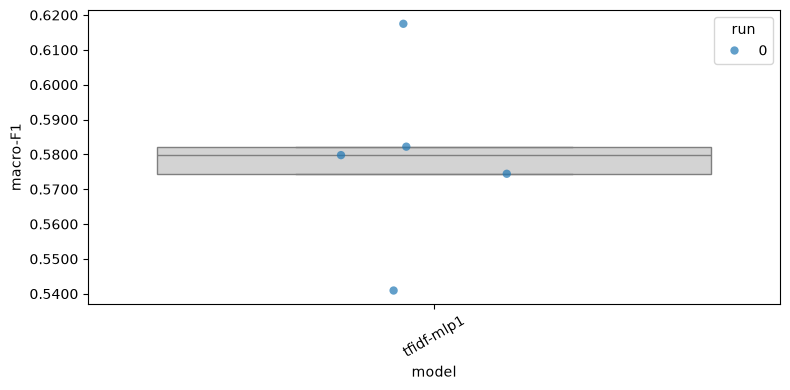

In [8]:
import pandas as pd

model_name = "tfidf-mlp1"

comparison = pd.DataFrame(data = {"model": model_name, "run": 0, "fold": list(folds), "macro-F1": scores})
summary = comparison.groupby(by = "model", sort = False)["macro-F1"].agg(func = ["mean", "std", "count"])
print(summary.to_string())
part1.analysis.plot_box_and_points(df = comparison, metric = "macro-F1")